# MLP Model

The following demos building a Multi-Layer Perceptron (MLP) model. The arguments used to build the model mirrors those found wiht the graph models.

## Import Modules

In [1]:
from mminer_graphs.model import MLP, EarlyStopping, summary
from mminer_graphs import Plots
import pandas as pd
import datamol as dm

## Dataset Prep
The sample dataset is taken from [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. This dataset includes quantitative (IC50) and qualitative (binary labels) binding results for inhibitors of human beta secretase (BACE-1). The only modification the dataset was replacing their default split with a random split and including cross-validation columns with random splits.

In this case, a model will be created using a single split (Model). After extracting the necessary information, the Data will contain the following format:

In [2]:
data = pd.read_csv("dataset/bace.csv")
cols = ['CID', 'smiles', 'Class', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

The shape of the dataset: (1513, 4)


,CID,smiles,Class,Model
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train


The dataset will need to be converted into graphs. Here, the data will be split into the train and test set (or also a validation set, but this is not used here). Using the MolToGraph() method, the molecules will be converted into graphs. By default, the AtomGraph will be used. Afterward, this information will be fed into the


In [3]:
train = dataset[dataset.iloc[:, -1] == 'train'].copy()
test = dataset[dataset.iloc[:, -1] == 'test'].copy()

train_mols = dm.from_df(train, smiles_column="smiles")
test_mols = dm.from_df(test, smiles_column="smiles")

## Molecular Fingerprint

The molecules will now be featureized. The MLP model is built to handle tabular data. In this exmaple, molecules are converted into ECFP Fingerprints. Four lists will be extracted - two lists containing the fingerprint for the train/test groups and two lists containing the labels for the train/test groups.

In [4]:
fp_list_train = []
train_labels = []
fp_list_test = []
test_labels = []
for x, label in zip(train_mols, train.Class):
    fp = dm.to_fp(x)
    fp_list_train.append(fp)
    train_labels.append(label)
for x, label in zip(test_mols, test.Class):
    fp = dm.to_fp(x)
    fp_list_test.append(fp)
    test_labels.append(label)

### Optional

The fingerprints can be appended to the input Dataframe. This can make it easier to save the file in a .csv format for sharing or for future parsing.

In [5]:
fp_df = pd.DataFrame(fp_list_train, index=train.index)
fp_df.columns = [f"fp_{i}" for i in range(fp_df.shape[1])]
train = pd.concat([train, fp_df], axis=1)
train.head()

,CID,smiles,Class,Model,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Train the Model

To train the model, the MLP class must be instantiated. There are several parameters that are needed, such as input size and the number of layers.

In this example, the 2048 fp bits are used as the input size and the hidden_size is set to 64. The model will be setup with three layers. Finally, the **reduce_size** argument will be set to False. If set to True, each subsequent layer nodes will be halved. This example will keep the nodes constant.

In [6]:
model = MLP(input_size=2048, hidden_size=64, layers=3, reduce_size=False)
model

MLP(
  (model): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=2048, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.0, inplace=False)
    )
    (1): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.0, inplace=False)
    )
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)

A summary of the model can be printed. This is wrapped from [torchinfo](https://github.com/TylerYep/torchinfo) and follows its basic usage.

In [7]:
summary(model, input_size=(1, 2048))

Layer (type:depth-idx)                   Output Shape              Param #
MLP                                      [1, 2]                    --
├─ModuleList: 1-1                        --                        --
│    └─Sequential: 2-1                   [1, 64]                   --
│    │    └─Linear: 3-1                  [1, 64]                   131,136
│    │    └─BatchNorm1d: 3-2             [1, 64]                   128
│    │    └─ReLU: 3-3                    [1, 64]                   --
│    │    └─Dropout: 3-4                 [1, 64]                   --
│    └─Sequential: 2-2                   [1, 64]                   --
│    │    └─Linear: 3-5                  [1, 64]                   4,160
│    │    └─BatchNorm1d: 3-6             [1, 64]                   128
│    │    └─ReLU: 3-7                    [1, 64]                   --
│    │    └─Dropout: 3-8                 [1, 64]                   --
│    └─Linear: 2-3                       [1, 2]                    130
Tota

**EarlyStopping** can also be used. Here it will be called to monitor the validation/test data.

In this tutorial, the **EarlyStopping** class is instantiated, but the patience is set at 5. It is only used here to give an example of how to use it. Its patience can be set accordingly.

In [8]:
estop = EarlyStopping(monitor='val_loss', patience=5, mode='min')

### Fit the Model

The model can be fitr in a similar fashion as the sklearn api by calling the **.fit()** instance method. There are several mandatory parameters needed to ensure that the model is fitted:
- The model train, test, train_labels, and test_labels.

All other arguments are optional or given by default.

In this model, the model will be trained on cpu and early stopping will be given as set in the cell above. Epochs will be set to 10.

In [9]:
model.fit(x_train=fp_list_train, y_train=train_labels, x_test=fp_list_test, y_test=test_labels, epochs=10, device="cpu", estop=estop)

Model and Tensor running on cpu


Epoch:  60%|██████    | 6/10 [00:00<00:00, 52.57it/s]

Early stopping triggered after 7 epochs!
Average Training Loss: 0.284
Average Test Loss: 0.568
Average Training Accuracy: 0.861
Average Test Accuracy: 0.784


## Plots

The mol-miner-graphs comes with basic plot functions. This section will demo their usage.

### Curves
The **curves()** method will generate the loss curve and accuracy curves for the model. It will use the results from the Test data. The figure here is drawn with default settings, however the **curves()** method contains additional parameters, such as line colors, figsize, or other metrics to plot (Precision).

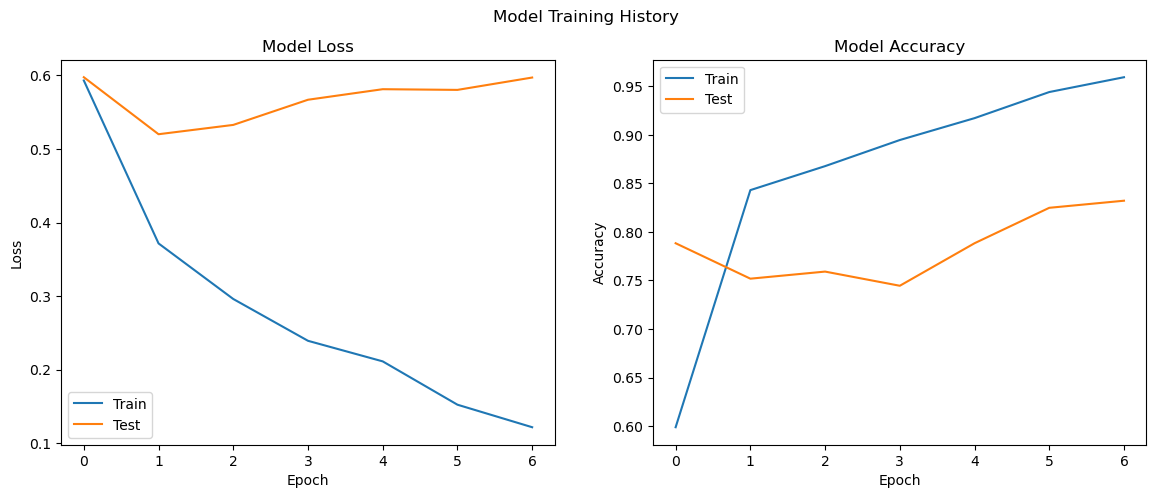

In [10]:
plot = Plots(model, x_test=fp_list_test, y_test=test_labels, device='cpu', batch_size=1024)

plot.curves()

### Confusion Matrix

A confusion matrix can be drawn using the **confusion_matrix()** method. The class names will default to 0 and 1. Here, they are renamed as "Inactive" and "Active" using the **class_names** parameter. The device is an important parameter and should be modified to use the same as the model fitting. For example, if the model was fitted using 'cpu', then the confusion matrix device should be set to 'cpu'. Additional parameters are available to modify the title, figsize, and cmap.

Prediction running on cpu


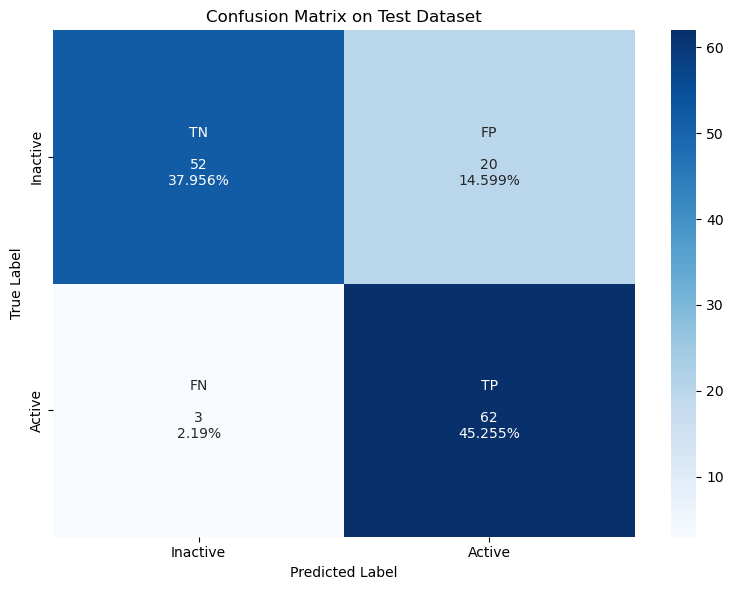

In [11]:
plot.confusion_matrix(class_names=['Inactive', 'Active'])

### Classificaiton Report
A classification report can also be generated. The parameters are similar to the **confusion_matrix()** method.

Prediction running on cpu


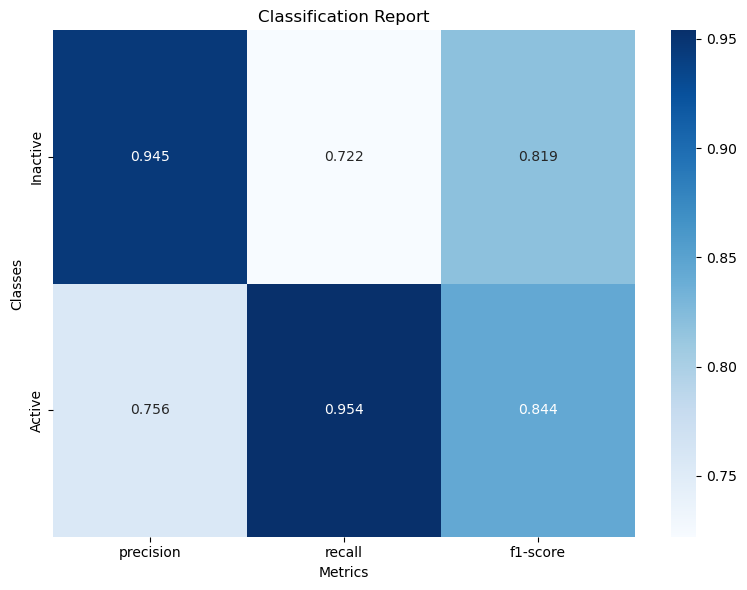

In [12]:
plot.classification_report(class_names=['Inactive', 'Active'])

## Making Predictions

Additionally, the mol-miner-graphs package contains a **.predict()** for easier usability. This will output a list of results on a tensor. By default, the **.predict()** method  it will output results as a list for easier use with pd.DataFrames. In this example, the results are given as a tensor. Users that wish to append this to a pd.DataFrame will need to convert the results using **.tolist()**

In [13]:
model.predict(data=fp_list_test, device="cpu", return_type="tensor", binary=True)

Prediction running on cpu


tensor([1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0])

### Save Model

Trained models can be saved using the **.save()** instance method. For PyTorch models, the [.pth file path](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) is used.

In [14]:
model.save("test.pth")

'Model saved!'

### Load Model

Models can be loaded from the .pth saved file by using the **.load()** instance method. Before calling using this, the model architecture must be called first. The model arguments must match to the saved .pth model. In this case, the example MLP model has an input_size of 2048, hidden_size of 64, and 3 layers.

In [15]:
model = MLP(input_size=2048, hidden_size=64, layers=3)
model.load("test.pth", device="cpu")
model

Model loaded!


MLP(
  (model): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=2048, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.0, inplace=False)
    )
    (1): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.0, inplace=False)
    )
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)